# Homework 8 — Supervised, Semi-Supervised, Unsupervised and Active Learning
Gao Wang · GitHub: Gavinfornever · USC ID: 8103152166

All data paths are relative to the repository root. Run all cells from a clean local Jupyter kernel. `M=30` and `M=50` are the assignment's requested Monte Carlo counts; the second experiment trains 90 models per run.
<style>
@media print {
  .highlight pre, .input_area pre, .output_area pre, pre {
    white-space: pre-wrap !important; overflow-wrap: anywhere !important;
    word-break: break-word !important; overflow: visible !important;
  }
  .input_area, .output_area { overflow: visible !important; }
  table { font-size: 9pt !important; max-width: 100% !important; }
}
</style>

## 1. Breast Cancer Wisconsin (Diagnostic)
### (a) Data and evaluation design
The positive class is malignant (`M=1`). In each of 30 runs, the test set contains exactly 20% of each class, selected without replacement. Scaling is fit on training data only; cross-validation is stratified and uses five folds. Test labels are used only for evaluation.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans, SpectralClustering
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

warnings.filterwarnings('ignore', category=ConvergenceWarning)
SEED = 552
M1, M2 = 30, 50
C_GRID = [0.01, 0.1, 1, 10]
data_dir = Path('data')
assert data_dir.exists(), 'Run this notebook from the repository root.'
breast = pd.read_csv(data_dir / 'wdbc.data', header=None)
Xb = breast.iloc[:, 2:].to_numpy(dtype=float)
yb = (breast.iloc[:, 1] == 'M').to_numpy(dtype=int)
print(f'Breast cancer: {Xb.shape[0]} records, {Xb.shape[1]} attributes; malignant={yb.sum()}, benign={(1-yb).sum()}')

Breast cancer: 569 records, 30 attributes; malignant=212, benign=357


In [2]:
def scores(y_true, y_pred, decision):
    return {'accuracy': accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'F1': f1_score(y_true, y_pred, zero_division=0),
            'AUC': roc_auc_score(y_true, decision) if len(np.unique(y_true)) == 2 else np.nan}

def tuned_l1(X, y):
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    model = make_pipeline(StandardScaler(), LinearSVC(penalty='l1', dual=False,
                                                      max_iter=3000, random_state=SEED))
    search = GridSearchCV(model, {'linearsvc__C': C_GRID}, cv=cv, scoring='accuracy', n_jobs=1)
    search.fit(X, y)
    return search.best_estimator_, search.best_params_['linearsvc__C']

def stratified_split(X, y, seed, test_fraction=0.2):
    rng = np.random.default_rng(seed)
    test = np.concatenate([rng.choice(np.flatnonzero(y == label),
                       size=round(np.sum(y == label) * test_fraction), replace=False)
                       for label in (0, 1)])
    train = np.setdiff1d(np.arange(len(y)), test)
    return train, test

def record_run(rows, example, method, run, split, y, pred, decision):
    rows.append({'method': method, 'run': run, 'split': split, **scores(y, pred, decision)})
    if run == 0:
        example[(method, split)] = (y.copy(), pred.copy(), decision.copy())

### (b)(i) Supervised L1 SVM
The same five-fold tuning procedure is used again when the initial labeled set is selected for self-training.

In [3]:
results, example = [], {}
splits = [stratified_split(Xb, yb, SEED + run) for run in range(M1)]
for run, (tr, te) in enumerate(splits):
    model, _ = tuned_l1(Xb[tr], yb[tr])
    for split, idx in [('train', tr), ('test', te)]:
        record_run(results, example, 'Supervised', run, split, yb[idx],
                   model.predict(Xb[idx]), model.decision_function(Xb[idx]))
print('Supervised: 30/30 runs complete')

Supervised: 30/30 runs complete


### (b)(ii) Semi-supervised self-training
Half of each training class is initially labeled. At every step, the unlabeled point with the largest absolute SVM decision value gets its predicted label. The L1 penalty is selected by five-fold CV on the initial labeled subset; subsequent fits use that selected penalty. This avoids tuning against untrusted pseudo-labels. Scaling is refit on the current labeled pool each step.

In [4]:
# AI prompt (scope: self-training selection): "Write a loop that selects the unlabeled point farthest from an L1 SVM hyperplane, pseudo-labels it, and refits without reading its true label."
for run, (tr, te) in enumerate(splits):
    rng = np.random.default_rng(SEED + 1000 + run)
    initial = np.concatenate([rng.choice(tr[yb[tr] == label],
                     size=len(tr[yb[tr] == label]) // 2, replace=False) for label in (0, 1)])
    unlabeled = np.setdiff1d(tr, initial)
    labeled = initial.copy()
    pseudo = yb[labeled].copy()
    model, chosen_c = tuned_l1(Xb[labeled], pseudo)
    while len(unlabeled):
        margin = np.abs(model.decision_function(Xb[unlabeled]))
        position = np.argmax(margin)
        selected = unlabeled[position]
        inferred = int(model.predict(Xb[selected:selected+1])[0])
        labeled = np.append(labeled, selected)
        pseudo = np.append(pseudo, inferred)
        unlabeled = np.delete(unlabeled, position)
        model = make_pipeline(StandardScaler(), LinearSVC(penalty='l1', dual=False,
                               C=chosen_c, max_iter=3000, random_state=SEED))
        model.fit(Xb[labeled], pseudo)
    for split, idx in [('train', tr), ('test', te)]:
        record_run(results, example, 'Self-training', run, split, yb[idx],
                   model.predict(Xb[idx]), model.decision_function(Xb[idx]))
print('Self-training: 30/30 runs complete')

Self-training: 30/30 runs complete


### (b)(iii) K-means, k=2
For each run, 20 random starts (`n_init=20`) are compared by inertia, reducing the risk of a poor local optimum. The 30 nearest training observations to each centroid vote on that cluster's class. Test points are assigned by the nearest training centroid. The continuous AUC score is the signed difference in distance to the benign and malignant centroids.

In [5]:
def majority_mapping(cluster, y, reference=None, mode='nearest30'):
    mapping = {}
    for group in (0, 1):
        members = np.flatnonzero(cluster == group)
        if mode == 'nearest30':
            members = members[np.argsort(reference[members, group])[:30]]
        mapping[group] = int(np.mean(y[members]) >= 0.5)
    return mapping

def cluster_score(distance, mapping):
    if mapping[0] != mapping[1]:
        positive = 0 if mapping[0] == 1 else 1
        negative = 1 - positive
        return distance[:, negative] - distance[:, positive]
    return np.full(len(distance), float(mapping[0]))

for run, (tr, te) in enumerate(splits):
    scaler = StandardScaler().fit(Xb[tr])
    xtr, xte = scaler.transform(Xb[tr]), scaler.transform(Xb[te])
    km = KMeans(n_clusters=2, n_init=20, random_state=SEED + run).fit(xtr)
    dtr, dte = km.transform(xtr), km.transform(xte)
    mapping = majority_mapping(km.labels_, yb[tr], dtr)
    for split, idx, d in [('train', tr, dtr), ('test', te, dte)]:
        pred = np.array([mapping[c] for c in np.argmin(d, axis=1)])
        record_run(results, example, 'K-means', run, split, yb[idx], pred, cluster_score(d, mapping))
print('K-means: 30/30 runs complete')

K-means: 30/30 runs complete


### (b)(iv) Spectral clustering with RBF kernel
Spectral clustering has no centroid or native out-of-sample `predict`. We use a transductive `fit_predict` on the combined unlabeled train/test feature matrix in each run, then determine cluster classes using training labels only. Test labels never influence fitting or mapping. Gamma=1, as specified. The AUC uses the binary cluster assignment as a coarse score; it is therefore less informative than a continuous SVM decision score.

Spectral clustering builds an RBF similarity graph, projects observations using eigenvectors of its graph Laplacian, then groups the embedding. With gamma=1 on these standardized features, the resulting clusters are highly imbalanced, which explains the near-majority-class performance below.

In [6]:
for run, (tr, te) in enumerate(splits):
    scaler = StandardScaler().fit(Xb[tr])
    combined = scaler.transform(Xb[np.r_[tr, te]])
    spectral = SpectralClustering(n_clusters=2, affinity='rbf', gamma=1.0,
                   assign_labels='kmeans', n_init=10, random_state=SEED + run)
    assignments = spectral.fit_predict(combined)
    train_groups = assignments[:len(tr)]
    mapping = majority_mapping(train_groups, yb[tr], mode='all')
    for split, idx, cluster in [('train', tr, train_groups),
                                ('test', te, assignments[len(tr):])]:
        pred = np.array([mapping[c] for c in cluster])
        record_run(results, example, 'Spectral', run, split, yb[idx], pred, pred.astype(float))
print('Spectral: 30/30 runs complete')

Spectral: 30/30 runs complete


### (b)(v) Comparison and example ROC/confusion matrices

accuracy        precision        recall            F1  \
                        mean    std      mean    std   mean    std   mean   
method        split                                                         
K-means       test     0.911  0.023     0.918  0.043  0.838  0.047  0.875   
              train    0.907  0.007     0.919  0.020  0.824  0.015  0.869   
Self-training test     0.965  0.016     0.970  0.029  0.935  0.032  0.952   
              train    0.977  0.006     0.981  0.014  0.956  0.012  0.968   
Spectral      test     0.631  0.004     0.267  0.450  0.006  0.011  0.012   
              train    0.631  0.001     1.000  0.000  0.010  0.003  0.020   
Supervised    test     0.967  0.019     0.964  0.032  0.948  0.035  0.955   
              train    0.986  0.006     0.991  0.006  0.972  0.011  0.981   

                              AUC         
                       std   mean    std  
method        split                       
K-means       test   0.033  0.974  0.012  
              train  0.010  0.973  0.004  
Self-training test   0.022  0.990  0.009  
              train  0.008  0.995  0.003  
Spectral      test   0.021  0.503  0.005  
              train  0.005  0.505  0.001  
Supervised    test   0.026  0.991  0.009  
              train  0.008  0.998  0.002

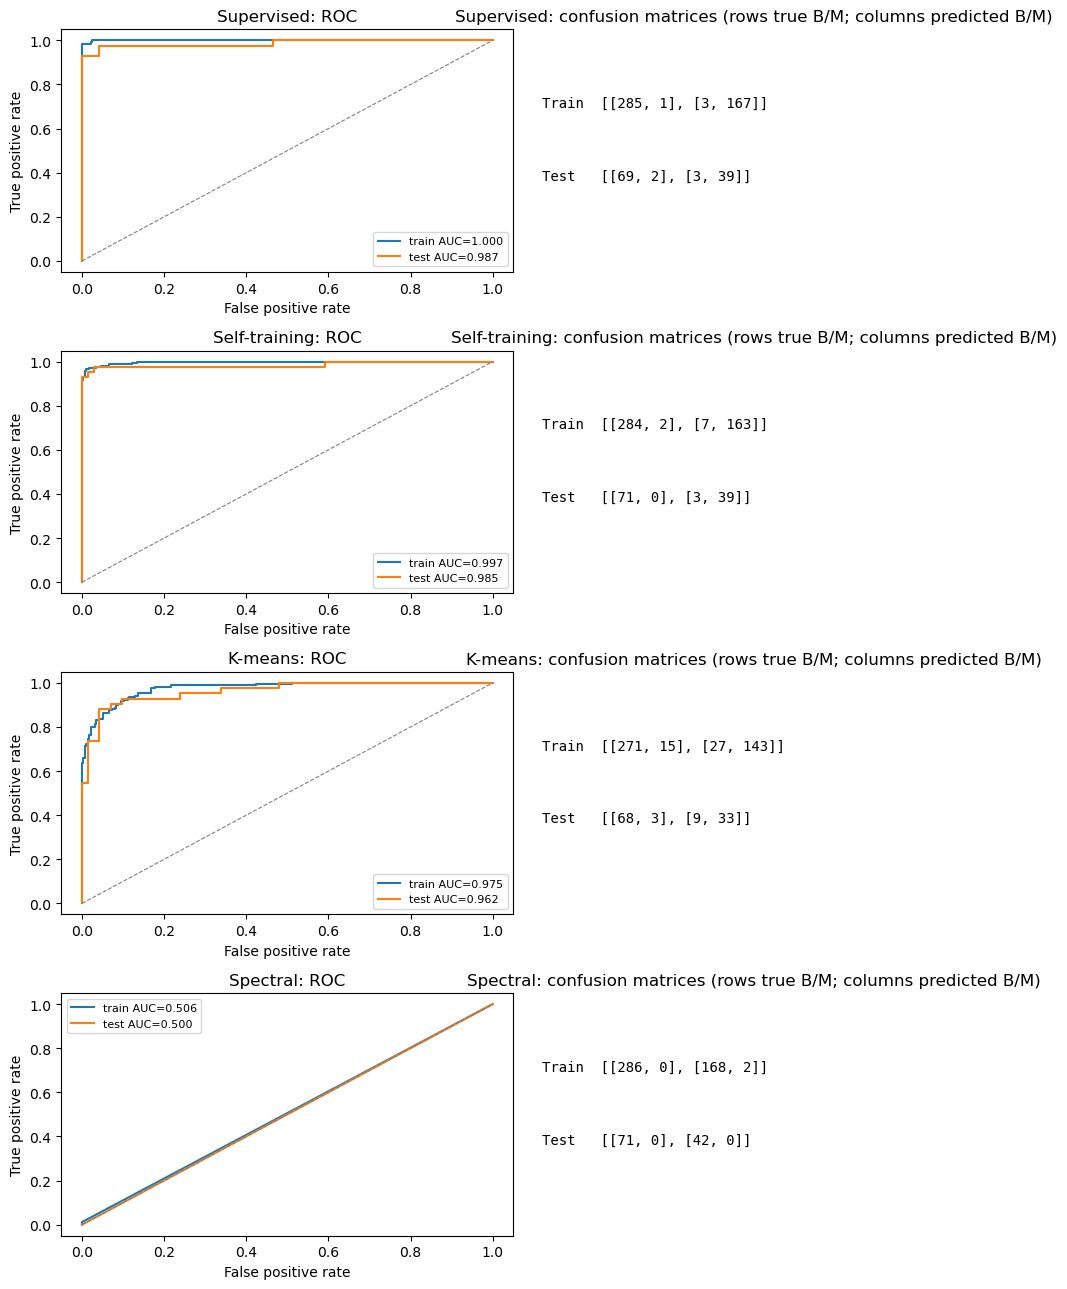

Highest mean test F1: Supervised (0.955)
Highest mean test AUC: Supervised (0.991)


In [7]:
summary = pd.DataFrame(results).groupby(['method', 'split'])[['accuracy','precision','recall','F1','AUC']].agg(['mean','std'])
display(summary.round(3))
methods = ['Supervised', 'Self-training', 'K-means', 'Spectral']
fig, axes = plt.subplots(4, 2, figsize=(10, 13))
for row, method in enumerate(methods):
    ax_roc, ax_cm = axes[row]
    for split, color in [('train','tab:blue'), ('test','tab:orange')]:
        y, pred, score = example[(method, split)]
        fpr, tpr, _ = roc_curve(y, score)
        ax_roc.plot(fpr, tpr, label=f'{split} AUC={roc_auc_score(y,score):.3f}', color=color)
    ax_roc.plot([0,1],[0,1], '--', color='gray', lw=0.8)
    ax_roc.set(title=f'{method}: ROC', xlabel='False positive rate', ylabel='True positive rate')
    ax_roc.legend(fontsize=8)
    cm_train = confusion_matrix(*example[(method,'train')][:2], labels=[0,1])
    cm_test = confusion_matrix(*example[(method,'test')][:2], labels=[0,1])
    ax_cm.axis('off')
    ax_cm.set_title(f'{method}: confusion matrices (rows true B/M; columns predicted B/M)')
    ax_cm.text(0.03, 0.68, f'Train  {cm_train.tolist()}', family='monospace', fontsize=10)
    ax_cm.text(0.03, 0.38, f'Test   {cm_test.tolist()}', family='monospace', fontsize=10)
plt.tight_layout()
plt.show()
test_means = summary.xs('test', level='split').xs('mean', axis=1, level=1)
print('Highest mean test F1:', test_means['F1'].idxmax(), f"({test_means['F1'].max():.3f})")
print('Highest mean test AUC:', test_means['AUC'].idxmax(), f"({test_means['AUC'].max():.3f})")

## 2. Active learning with banknote authentication
### (a) Data split
For each of 50 repetitions, select 472 test observations and 900 training observations. Passive and active learners share that split and an initial labeled pool of exactly five examples from each class. Neither method reuses a selected example. Five-fold CV chooses the L1 linear SVM penalty at each pool size. The small logarithmic grid keeps the full 9,000-model Monte Carlo experiment practical.

In [8]:
bank = pd.read_csv(data_dir / 'data_banknote_authentication.txt', header=None)
Xn = bank.iloc[:, :4].to_numpy(dtype=float)
yn = bank.iloc[:, 4].to_numpy(dtype=int)
assert Xn.shape == (1372, 4) and set(np.unique(yn)) == {0, 1}
print(f'Banknote: {len(yn)} records; class counts={np.bincount(yn).tolist()}')

def bank_run(seed):
    rng = np.random.default_rng(seed)
    tr, te = train_test_split(np.arange(len(yn)), train_size=900, random_state=seed,
                              stratify=yn)
    initial = np.concatenate([rng.choice(tr[yn[tr] == label], size=5, replace=False)
                              for label in (0, 1)])
    remaining = np.setdiff1d(tr, initial)
    passive_order = rng.permutation(remaining)
    passive_pool = list(initial)
    active_pool = list(initial)
    active_remaining = remaining.copy()
    passive_errors, active_errors = [], []
    for step in range(90):
        passive_model, _ = tuned_l1(Xn[passive_pool], yn[passive_pool])
        active_model, _ = tuned_l1(Xn[active_pool], yn[active_pool])
        passive_errors.append(1 - accuracy_score(yn[te], passive_model.predict(Xn[te])))
        active_errors.append(1 - accuracy_score(yn[te], active_model.predict(Xn[te])))
        if step < 89:
            passive_pool.extend(passive_order[step*10:(step+1)*10])
            # AI prompt (scope: active batch selection): "From only the remaining training pool, add the ten points nearest the current L1 SVM hyperplane; do not replace selected points."
            distances = np.abs(active_model.decision_function(Xn[active_remaining]))
            chosen_positions = np.argsort(distances)[:10]
            active_pool.extend(active_remaining[chosen_positions])
            active_remaining = np.delete(active_remaining, chosen_positions)
    assert len(passive_pool) == len(active_pool) == 900
    return passive_errors, active_errors

passive, active = [], []
for run in range(M2):
    p, a = bank_run(SEED + 2000 + run)
    passive.append(p)
    active.append(a)
    if (run + 1) % 10 == 0: print(f'Banknote Monte Carlo: {run+1}/{M2} runs complete')
passive, active = np.array(passive), np.array(active)
assert passive.shape == active.shape == (50, 90)

Banknote: 1372 records; class counts=[762, 610]
Banknote Monte Carlo: 10/50 runs complete
Banknote Monte Carlo: 20/50 runs complete
Banknote Monte Carlo: 30/50 runs complete
Banknote Monte Carlo: 40/50 runs complete
Banknote Monte Carlo: 50/50 runs complete


### (b)–(c) Learning curves and conclusion
Each plotted point is the mean of 50 test errors at the same pool size; the shaded band is ±1 standard deviation. The table reports selected pool sizes and the mean error across all 90 sizes for each method.

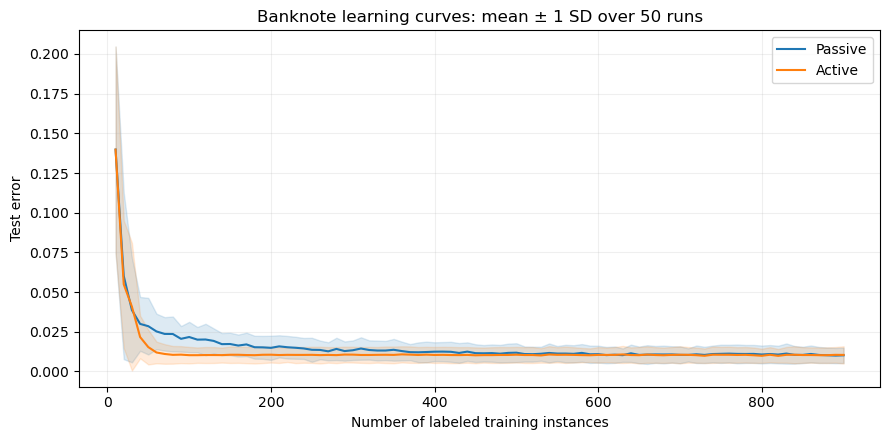

,pool size,passive mean test error,active mean test error
0,10,0.140,0.140
1,50,0.029,0.015
2,100,0.022,0.010
3,200,0.015,0.011
4,500,0.012,0.011
5,900,0.010,0.010


Mean across all 90 pool sizes: passive=0.0156, active=0.0129
Active has lower mean error at 80 of 90 pool sizes.


In [9]:
sizes = np.arange(10, 901, 10)
fig, ax = plt.subplots(figsize=(9, 4.5))
for values, label, color in [(passive,'Passive','tab:blue'), (active,'Active','tab:orange')]:
    mean = values.mean(axis=0)
    sd = values.std(axis=0, ddof=1)
    ax.plot(sizes, mean, label=label, color=color)
    ax.fill_between(sizes, np.maximum(0,mean-sd), mean+sd, color=color, alpha=0.15)
ax.set(xlabel='Number of labeled training instances', ylabel='Test error',
       title='Banknote learning curves: mean ± 1 SD over 50 runs')
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
display(pd.DataFrame({'pool size':sizes[[0,4,9,19,49,89]],
    'passive mean test error':passive.mean(axis=0)[[0,4,9,19,49,89]],
    'active mean test error':active.mean(axis=0)[[0,4,9,19,49,89]]}).round(3))
print(f'Mean across all 90 pool sizes: passive={passive.mean():.4f}, active={active.mean():.4f}')
print(f'Active has lower mean error at {int(np.sum(active.mean(axis=0) < passive.mean(axis=0)))} of 90 pool sizes.')

### Interpretation and references
Across 30 runs, the supervised model had the highest mean test F1 (0.955) and AUC (0.991). Self-training was close (F1 0.952, AUC 0.990), while k-means was weaker (F1 0.875, AUC 0.974). Spectral clustering with the permitted gamma=1 was poor (F1 0.012, AUC 0.503): its graph partition isolated very few malignant observations. Accuracy around 0.631 therefore reflects the majority benign class and should not be read as strong classification. A different gamma or a balance constraint could change that outcome. Spectral test predictions are transductive: they use test features but never test labels.

Across 50 banknote repetitions, active learning had a lower mean test error than passive learning at 80 of 90 pool sizes, with overall means of 0.0129 versus 0.0156. At 900 labels the methods converged to about 0.010. Selection near the decision boundary was most helpful at smaller pool sizes.

Sources: [UCI Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic); [UCI Banknote Authentication](https://archive.ics.uci.edu/dataset/267/banknote+authentication); [scikit-learn SpectralClustering](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html).